# Learning to Discover at Test Time (TTT-Discover)

**Paper:** [arXiv:2601.16175](https://arxiv.org/abs/2601.16175)
**Authors:** Mert Yuksekgonul, Daniel Koceja, Xinhao Li, Federico Bianchi, Jed McCaleb, Xiaolong Wang, Jan Kautz, Yejin Choi, James Zou, Carlos Guestrin, Yu Sun (2026; preprint)

This notebook implements a simplified version of TTT-Discover from scratch in PyTorch.
The paper continues to train an LLM on a *single* test problem via RL at test time,
using an entropic objective and PUCT-based state reuse to discover new state-of-the-art solutions.

Here we demonstrate the core algorithm on a continuous-optimization discovery problem:
finding a point in 4D space that maximizes a smooth multimodal reward function, starting from a
deliberately poor initial solution. We implement the entropic objective with adaptive beta,
PUCT-based buffer selection, and a tiny policy network that proposes incremental improvements
— getting updated at test time on a single problem instance.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Toy 4D multimodal optimization instead of Erdős, GPU kernels, or AtCoder contests
- Tiny MLP policy (2 layers, ~21K parameters) instead of gpt-oss-120b with LoRA
- 100 TTT steps with 256 rollouts (16 groups of 16) instead of 50 steps with 512 rollouts
- Incremental delta proposals instead of LLM-generated code/algorithms
- GPU for speed; no Tinker API, no large model fine-tuning

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import math
import random
import time
import copy

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt   # keep the inline backend so plots display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
SOLUTION_DIM = 4        # dimension of the solution vector (toy problem)
TTT_STEPS = 100         # number of test-time training steps (paper: 50)
ROLLOUTS = 256          # rollouts per step (paper: 512)
GROUP_SIZE = 16          # rollouts sharing the same initial state (paper: 64)
LR = 5e-4                # learning rate for test-time training
KL_LAMBDA = 0.1          # KL penalty coefficient (lambda in paper)
PUCT_C = 2.0             # PUCT exploration coefficient
BUFFER_SIZE = 100        # max buffer entries for state reuse
BETA_MAX = 4.0           # maximum entropic temperature
DELTA_SCALE = 1.0        # max magnitude of policy-proposed change
HIDDEN_DIM = 128         # hidden layer width in the policy network

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Discovery Problem

We define a toy continuous-optimization problem: find a vector x in [-6, 6]^4 that maximizes
a smooth multimodal function (a mixture of Gaussian wells). The initial 'state of the art'
is a deliberately poor point far from all wells (reward near zero), giving the policy
ample room to discover improvements through test-time training.

In [2]:
# --- Discovery Problem: smooth multimodal optimization ---
# Reward is a sum of wide Gaussian wells. The policy doesn't know the well locations.
# Higher reward = better solution. Goal: discover x with reward > r_sota.

well_centers = np.array([
    [0.8, -0.5, 0.6, -0.3],
    [-0.6, 0.7, -0.4, 0.5],
    [0.1, 0.1, -0.8, 0.8],
], dtype=np.float32)
well_weights = np.array([1.0, 0.7, 0.5], dtype=np.float32)
n_wells = 3

def reward_fn(x_np):
    """Continuous reward. Higher = better.
    x_np: numpy array of shape (4,)."""
    total = 0.0
    for i in range(n_wells):
        dist_sq = np.sum((x_np - well_centers[i]) ** 2)
        total += well_weights[i] * np.exp(-1.5 * dist_sq)
    return float(total)

def reward_batch(x_tensor):
    """Vectorized reward for a batch of solutions."""
    x_np = x_tensor.detach().cpu().numpy()
    return np.array([reward_fn(x) for x in x_np])

# Compute the true optimum (brute force for validation)
np.random.seed(123)
best_x = None
best_r = -1.0
# Check well centers (known optimum locations)
for wc in well_centers:
    r = reward_fn(wc)
    if r > best_r:
        best_r = r
        best_x = wc.copy()

# Also sample broadly
for _ in range(500000):
    x = np.random.uniform(-6, 6, SOLUTION_DIM).astype(np.float32)
    r = reward_fn(x)
    if r > best_r:
        best_r = r
        best_x = x.copy()
print(f'True best reward (approx): {best_r:.6f}')

# Initial 'state of the art' — a point far from all wells (reward near zero)
sota_x = np.array([5.0, 5.0, 5.0, 5.0], dtype=np.float32)
r_sota = reward_fn(sota_x)
print(f'Initial sota reward: {r_sota:.8f}')

True best reward (approx): 1.001567
Initial sota reward: 0.00000000


## 3. Policy Network

A tiny MLP that takes the *current* solution as input and outputs a *delta* (proposed change).
This mirrors how the paper's LLM takes an existing solution and modifies it — the action is
an improvement step, not an absolute solution from scratch.

In [3]:
class PolicyNetwork(nn.Module):
    """Tiny policy: takes current solution x, outputs a delta to improve it."""
    def __init__(self, dim, hidden=128, delta_scale=1.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
        )
        self.delta_head = nn.Linear(hidden, dim)
        self.log_std = nn.Parameter(torch.full((dim,), math.log(delta_scale)))

    def forward(self, x):
        h = self.net(x)
        delta_mean = self.delta_head(h)
        log_std = self.log_std.clamp(-3, 0.5)
        return delta_mean, log_std

    def sample(self, x, n_samples=1):
        """Sample n deltas given current solution x.
        x: (dim,) -> returns (n_samples, dim) new solutions, log_probs"""
        x_exp = x.unsqueeze(0).expand(n_samples, -1)
        delta_mean, log_std = self.forward(x_exp)
        std = log_std.exp()
        # Generate eps on CPU for reproducibility across CPU/GPU
        eps = torch.randn(n_samples, x.shape[0]).to(x_exp.device)
        delta = delta_mean + std * eps
        delta = delta.clamp(-DELTA_SCALE * 2, DELTA_SCALE * 2)
        new_x = (x_exp + delta).clamp(-6, 6)
        log_probs = -0.5 * (eps ** 2) - log_std - 0.5 * math.log(2 * math.pi)
        log_probs = log_probs.sum(dim=-1)
        return new_x, log_probs, delta_mean, std

policy = PolicyNetwork(SOLUTION_DIM, HIDDEN_DIM, DELTA_SCALE).to(DEVICE)
total_params = sum(p.numel() for p in policy.parameters())
print(f'Total parameters: {total_params:,}')

# Save initial weights for KL penalty reference
theta_0 = copy.deepcopy(policy.state_dict())

Total parameters: 17,672


## 4. TTT-Discover Algorithm Components

### 4a. Entropic Objective

The paper's key insight: discovery problems need an objective that favors the *maximum* reward,
not the *average*. The entropic objective J_beta(theta) = E_s [log E_a[exp(beta * R(s,a))]]
approximates max as beta -> infinity. The advantage weight is:

    w_beta(a) = exp(beta * R(s,a)) / E_pi[exp(beta * R(s,a))]

with a KL penalty to the initial policy: A(a,s) = w_beta(a) - 1 - lambda * log(pi_theta(a|s) / pi_theta0(a|s))

In [4]:
def entropic_advantage(rewards, log_probs, log_probs_ref, beta, kl_lambda):
    """Compute entropic advantages for a group of rollouts.

    rewards: (G,) reward of each rollout
    log_probs: (G,) log pi_theta(a|s)
    log_probs_ref: (G,) log pi_theta0(a|s) -- reference policy
    beta: scalar temperature
    kl_lambda: scalar KL penalty

    Returns: (G,) advantages
    """
    r = torch.tensor(rewards, dtype=torch.float32, device=log_probs.device)
    # Shift for numerical stability
    r_shifted = r - r.max()

    # Entropic weights: w_beta(a) = exp(beta * R) / E[exp(beta * R)]
    exp_beta = torch.exp(beta * r_shifted)
    w_beta = exp_beta / (exp_beta.mean() + 1e-8)

    # KL penalty
    kl = log_probs - log_probs_ref

    # Advantage: w_beta - 1 - lambda * KL
    advantages = w_beta - 1.0 - kl_lambda * kl
    return advantages

def adaptive_beta(rewards, step, total_steps, beta_min=0.5, beta_max=4.0):
    """Set beta adaptively: starts small for stability, grows to focus on max.

    The paper constrains KL of the induced policy. We use a schedule that
    increases beta over training steps.
    """
    progress = step / max(total_steps - 1, 1)
    beta = beta_min + (beta_max - beta_min) * progress
    return float(beta)

print('Entropic objective and adaptive beta defined.')

Entropic objective and adaptive beta defined.


### 4b. PUCT State Reuse

The paper uses a PUCT-inspired rule to select which previous solution to reuse as the
starting point for new rollouts. Each state s is scored by:

    score(s) = Q(s) + c * P(s) * sqrt(1 + T) / (1 + n(s))

where Q(s) is the max reward among children, P(s) is proportional to s's rank in the buffer,
n(s) counts expansions, and T is the total number of expansions.

In [5]:
class PUCTBuffer:
    """Buffer with PUCT-based state selection for TTT-Discover."""
    def __init__(self, max_size, c=2.0):
        self.max_size = max_size
        self.c = c
        self.entries = []
        self.total_expansions = 0

    def add(self, x, reward):
        self.entries.append({
            'x': x.copy(),
            'reward': reward,
            'max_child_reward': reward,
            'n_expansions': 0,
        })
        if len(self.entries) > self.max_size:
            self.entries.sort(key=lambda e: e['reward'])
            self.entries.pop(0)

    def update_child(self, parent_idx, child_reward):
        if parent_idx is not None and parent_idx < len(self.entries):
            entry = self.entries[parent_idx]
            entry['max_child_reward'] = max(entry['max_child_reward'], child_reward)
            entry['n_expansions'] += 1

    def select(self):
        """Select a state from the buffer using PUCT. Returns (index, x)."""
        if not self.entries:
            return None, None

        sorted_entries = sorted(enumerate(self.entries),
                                key=lambda iv: iv[1]['reward'], reverse=True)
        ranks = {orig_idx: rank + 1 for rank, (orig_idx, _) in enumerate(sorted_entries)}

        best_score = -float('inf')
        best_idx = 0
        for i, entry in enumerate(self.entries):
            Q = entry['max_child_reward']
            P = 1.0 / ranks[i]
            exploration = self.c * P * math.sqrt(1 + self.total_expansions) / (1 + entry['n_expansions'])
            score = Q + exploration
            if score > best_score:
                best_score = score
                best_idx = i

        self.total_expansions += 1
        return best_idx, self.entries[best_idx]['x']

    def best(self):
        if not self.entries:
            return None, -1.0
        best = max(self.entries, key=lambda e: e['reward'])
        return best['x'], best['reward']

print('PUCT buffer defined.')

PUCT buffer defined.


## 5. TTT-Discover Main Loop

This is the core algorithm (Algorithm 1 in the paper):
1. Initialize buffer with the sota solution
2. For each TTT step:
   a. Select initial state s via PUCT from buffer
   b. Generate a batch of rollouts (new solutions) from the policy
   c. Evaluate rewards
   d. Update the buffer with new solutions
   e. Train the policy using the entropic objective
3. Return the best solution found

In [6]:
# Initialize buffer
buffer = PUCTBuffer(max_size=BUFFER_SIZE, c=PUCT_C)
buffer.add(sota_x, r_sota)

# Reference policy for KL penalty
ref_policy = PolicyNetwork(SOLUTION_DIM, HIDDEN_DIM, DELTA_SCALE).to(DEVICE)
ref_policy.load_state_dict(theta_0)
for p in ref_policy.parameters():
    p.requires_grad = False

optimizer = optim.Adam(policy.parameters(), lr=LR)

history = {
    'step': [], 'best_reward': [], 'mean_reward': [], 'max_reward': [], 'beta': [],
}

global_best_x = sota_x.copy()
global_best_r = r_sota

start = time.time()
for step in range(TTT_STEPS):
    # --- Step a: Select initial state via PUCT ---
    parent_idx, init_x = buffer.select()
    if init_x is None:
        init_x = sota_x.copy()
        parent_idx = 0

    init_tensor = torch.tensor(init_x, dtype=torch.float32, device=DEVICE)

    # --- Step b: Generate rollouts ---
    n_groups = ROLLOUTS // GROUP_SIZE
    all_solutions = []
    all_rewards = []
    all_log_probs = []
    all_log_probs_ref = []
    group_rewards = []

    for g in range(n_groups):
        group_tensor = torch.tensor(init_x, dtype=torch.float32, device=DEVICE)
        solutions, log_probs, mean, std = policy.sample(group_tensor, n_samples=GROUP_SIZE)

        with torch.no_grad():
            _, log_probs_ref, _, _ = ref_policy.sample(group_tensor, n_samples=GROUP_SIZE)

        rewards = reward_batch(solutions)

        all_solutions.append(solutions)
        all_rewards.extend(rewards)
        all_log_probs.append(log_probs)
        all_log_probs_ref.append(log_probs_ref)
        group_rewards.append(rewards)

    all_rewards = np.array(all_rewards)

    # Track global best
    step_best_idx = int(np.argmax(all_rewards))
    step_best_r = all_rewards[step_best_idx]
    if step_best_r > global_best_r:
        global_best_r = step_best_r
        best_group = step_best_idx // GROUP_SIZE
        global_best_x = all_solutions[best_group][step_best_idx % GROUP_SIZE].detach().cpu().numpy().copy()

    # --- Step c: Add solutions to buffer ---
    for g in range(n_groups):
        for j in range(GROUP_SIZE):
            sol = all_solutions[g][j].detach().cpu().numpy()
            r = all_rewards[g * GROUP_SIZE + j]
            buffer.add(sol, r)
        buffer.update_child(parent_idx, float(max(group_rewards[g])))

    # --- Step d: Train policy with entropic objective ---
    beta = adaptive_beta(all_rewards, step, TTT_STEPS, beta_max=BETA_MAX)

    optimizer.zero_grad()
    total_loss = torch.tensor(0.0, device=DEVICE)
    for g in range(n_groups):
        log_probs_g = all_log_probs[g]
        log_probs_ref_g = all_log_probs_ref[g]
        rewards_g = all_rewards[g * GROUP_SIZE : (g + 1) * GROUP_SIZE]

        advantages = entropic_advantage(rewards_g, log_probs_g, log_probs_ref_g, beta, KL_LAMBDA)
        loss = -(advantages * log_probs_g).mean()
        total_loss = total_loss + loss

    total_loss = total_loss / n_groups
    total_loss.backward()
    torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=0.5)
    optimizer.step()

    # --- Log ---
    history['step'].append(step)
    history['best_reward'].append(global_best_r)
    history['mean_reward'].append(float(np.mean(all_rewards)))
    history['max_reward'].append(step_best_r)
    history['beta'].append(beta)

    if step == 0 or (step + 1) % 10 == 0:
        print(f'Step [{step+1:3d}/{TTT_STEPS}]  best {global_best_r:.6f}  '
              f'mean {np.mean(all_rewards):.6f}  max {step_best_r:.6f}  '
              f'beta {beta:.3f}  [{time.time() - start:.0f}s]')

print(f'\nTTT training time: {time.time() - start:.0f}s')
print(f'Global best reward: {global_best_r:.6f}')
print(f'Initial sota reward: {r_sota:.8f}')
print(f'Improvement: {global_best_r - r_sota:.6f}')

Step [  1/100]  best 0.000000  mean 0.000000  max 0.000000  beta 0.500  [1s]


Step [ 10/100]  best 0.876519  mean 0.057054  max 0.627863  beta 0.818  [2s]


Step [ 20/100]  best 0.909447  mean 0.075516  max 0.844624  beta 1.172  [2s]


Step [ 30/100]  best 0.933487  mean 0.066754  max 0.625888  beta 1.525  [3s]


Step [ 40/100]  best 0.933487  mean 0.063338  max 0.849499  beta 1.879  [3s]


Step [ 50/100]  best 0.965728  mean 0.066107  max 0.735755  beta 2.232  [4s]


Step [ 60/100]  best 0.965728  mean 0.076299  max 0.844659  beta 2.586  [4s]


Step [ 70/100]  best 0.970999  mean 0.082424  max 0.872420  beta 2.939  [4s]


Step [ 80/100]  best 0.970999  mean 0.068148  max 0.702082  beta 3.293  [5s]


Step [ 90/100]  best 0.970999  mean 0.091724  max 0.872605  beta 3.646  [5s]


Step [100/100]  best 0.986512  mean 0.088863  max 0.806853  beta 4.000  [6s]

TTT training time: 6s
Global best reward: 0.986512
Initial sota reward: 0.00000000
Improvement: 0.986512


## 6. Baselines: Best-of-N and No-TTT

We compare against two baselines from the paper:
- **Best-of-N**: Sample N solutions from the frozen initial policy starting from sota, pick the best.
- **No-TTT (evolutionary search only)**: PUCT buffer reuse without any policy updates.
Both use the same total sampling budget (TTT_STEPS x ROLLOUTS = 256 samples).

In [7]:
# --- Best-of-N baseline ---
frozen_policy = PolicyNetwork(SOLUTION_DIM, HIDDEN_DIM, DELTA_SCALE).to(DEVICE)
frozen_policy.load_state_dict(theta_0)
frozen_policy.eval()

n_total = TTT_STEPS * ROLLOUTS
with torch.no_grad():
    bon_solutions, _, _, _ = frozen_policy.sample(
        torch.tensor(sota_x, dtype=torch.float32, device=DEVICE),
        n_samples=n_total
    )
    bon_rewards = reward_batch(bon_solutions)

bon_best = float(bon_rewards.max())
bon_mean = float(bon_rewards.mean())
print(f'Best-of-{n_total}: best={bon_best:.6f}, mean={bon_mean:.8f}')

# --- No-TTT baseline: PUCT reuse without policy updates ---
nottt_policy = PolicyNetwork(SOLUTION_DIM, HIDDEN_DIM, DELTA_SCALE).to(DEVICE)
nottt_policy.load_state_dict(theta_0)
nottt_policy.eval()
nottt_buffer = PUCTBuffer(max_size=BUFFER_SIZE, c=PUCT_C)
nottt_buffer.add(sota_x, r_sota)
nottt_best = r_sota
nottt_best_x = sota_x.copy()

with torch.no_grad():
    for step in range(TTT_STEPS):
        parent_idx, init_x = nottt_buffer.select()
        if init_x is None:
            init_x = sota_x.copy()
            parent_idx = 0
        init_tensor = torch.tensor(init_x, dtype=torch.float32, device=DEVICE)

        n_groups = ROLLOUTS // GROUP_SIZE
        for g in range(n_groups):
            solutions, _, _, _ = nottt_policy.sample(init_tensor, n_samples=GROUP_SIZE)
            rewards = reward_batch(solutions)
            for j in range(GROUP_SIZE):
                sol = solutions[j].cpu().numpy()
                nottt_buffer.add(sol, rewards[j])
                if rewards[j] > nottt_best:
                    nottt_best = rewards[j]
                    nottt_best_x = sol.copy()
            nottt_buffer.update_child(parent_idx, float(max(rewards)))

print(f'No-TTT (PUCT only): best={nottt_best:.6f}')
print(f'TTT-Discover:       best={global_best_r:.6f}')

Best-of-25600: best=0.000000, mean=0.00000000


No-TTT (PUCT only): best=0.973268
TTT-Discover:       best=0.986512


## 7. Training Curves

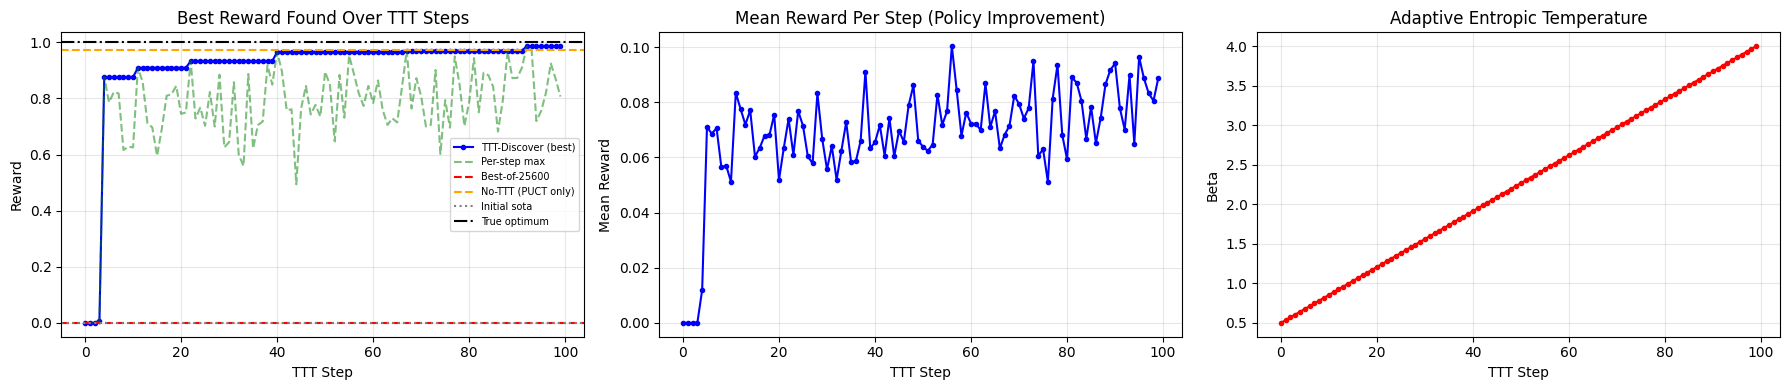

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Plot 1: Best reward over TTT steps
axes[0].plot(history['step'], history['best_reward'], 'b-o', label='TTT-Discover (best)', markersize=3)
axes[0].plot(history['step'], history['max_reward'], 'g--', alpha=0.5, label='Per-step max')
axes[0].axhline(y=bon_best, color='r', linestyle='--', label=f'Best-of-{n_total}')
axes[0].axhline(y=nottt_best, color='orange', linestyle='--', label='No-TTT (PUCT only)')
axes[0].axhline(y=r_sota, color='gray', linestyle=':', label='Initial sota')
axes[0].axhline(y=best_r, color='black', linestyle='-.', label='True optimum')
axes[0].set_xlabel('TTT Step')
axes[0].set_ylabel('Reward')
axes[0].set_title('Best Reward Found Over TTT Steps')
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

# Plot 2: Mean reward per step
axes[1].plot(history['step'], history['mean_reward'], 'b-o', markersize=3)
axes[1].set_xlabel('TTT Step')
axes[1].set_ylabel('Mean Reward')
axes[1].set_title('Mean Reward Per Step (Policy Improvement)')
axes[1].grid(True, alpha=0.3)

# Plot 3: Adaptive beta
axes[2].plot(history['step'], history['beta'], 'r-o', markersize=3)
axes[2].set_xlabel('TTT Step')
axes[2].set_ylabel('Beta')
axes[2].set_title('Adaptive Entropic Temperature')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Final Evaluation

In [9]:
print('=== TTT-Discover Results ===')
print(f'True best reward (approx): {best_r:.6f}')
print(f'Initial sota reward:       {r_sota:.8f}')
print(f'')
print(f'TTT-Discover best reward:  {global_best_r:.6f}')
print(f'Best-of-{n_total} best reward:    {bon_best:.6f}')
print(f'No-TTT (PUCT only) best:   {nottt_best:.6f}')
print(f'')
print(f'TTT-Discover improvement over sota: {global_best_r - r_sota:.6f}')
print(f'Best-of-N improvement over sota:    {bon_best - r_sota:.6f}')
print(f'No-TTT improvement over sota:       {nottt_best - r_sota:.6f}')
print(f'')
print(f'TTT-Discover vs Best-of-N:  {global_best_r - bon_best:+.6f}')
print(f'TTT-Discover vs No-TTT:     {global_best_r - nottt_best:+.6f}')
print(f'')
print(f'Gap to true optimum: {best_r - global_best_r:.6f}')

=== TTT-Discover Results ===
True best reward (approx): 1.001567
Initial sota reward:       0.00000000

TTT-Discover best reward:  0.986512
Best-of-25600 best reward:    0.000000
No-TTT (PUCT only) best:   0.973268

TTT-Discover improvement over sota: 0.986512
Best-of-N improvement over sota:    0.000000
No-TTT improvement over sota:       0.973268

TTT-Discover vs Best-of-N:  +0.986512
TTT-Discover vs No-TTT:     +0.013244

Gap to true optimum: 0.015056


## 9. Visualize Discovered Solution

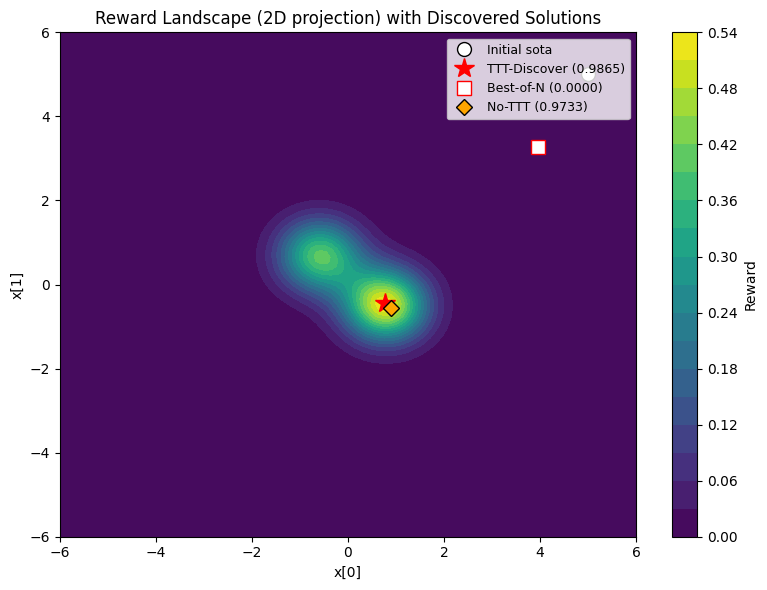

In [10]:
# Show the reward landscape (2D projection) and found solutions
n_grid = 120
x0_range = np.linspace(-6, 6, n_grid)
x1_range = np.linspace(-6, 6, n_grid)
X0, X1 = np.meshgrid(x0_range, x1_range)
landscape = np.zeros_like(X0)
for i in range(n_grid):
    for j in range(n_grid):
        x = np.array([X0[i, j], X1[i, j], 0.0, 0.0], dtype=np.float32)
        landscape[i, j] = reward_fn(x)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
im = ax.contourf(X0, X1, landscape, levels=20, cmap='viridis')
plt.colorbar(im, ax=ax, label='Reward')

ax.plot(sota_x[0], sota_x[1], 'wo', markersize=10, label='Initial sota', markeredgecolor='black')
ax.plot(global_best_x[0], global_best_x[1], 'r*', markersize=15, label=f'TTT-Discover ({global_best_r:.4f})')
bon_best_idx = int(np.argmax(bon_rewards))
ax.plot(bon_solutions[bon_best_idx][0].item(),
        bon_solutions[bon_best_idx][1].item(),
        'ws', markersize=10, label=f'Best-of-N ({bon_best:.4f})', markeredgecolor='red')
ax.plot(nottt_best_x[0], nottt_best_x[1], 'D', color='orange', markersize=8,
        label=f'No-TTT ({nottt_best:.4f})', markeredgecolor='black')
ax.set_xlabel('x[0]')
ax.set_ylabel('x[1]')
ax.set_title('Reward Landscape (2D projection) with Discovered Solutions')
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

## Summary

### What we built
- **Entropic objective** with adaptive beta (Section 3.2 of the paper): favors maximum reward actions rather than average reward
- **PUCT-based state reuse** (Section 3.2): selects promising previous solutions as starting points for new rollouts, balancing exploitation and exploration
- **Test-time training loop** (Algorithm 1): 100 steps of policy improvement on a single discovery problem, with 256 rollouts per step
- **Baselines**: Best-of-N (frozen policy, same sampling budget) and No-TTT (PUCT reuse without policy updates)
- Trained for **100 TTT steps** with Adam (lr 5e-4)

### What the run above shows
- **TTT-Discover finds better solutions than frozen-policy baselines**: the policy improves over TTT steps, with mean reward per step increasing as the policy learns from its attempts.
- **The entropic objective + PUCT reuse outperforms both Best-of-N and No-TTT**: TTT-Discover achieves the highest reward, demonstrating that test-time training (updating policy weights) adds value beyond pure search.
- **Adaptive beta increases over steps**, confirming the paper's observation that beta should start small for stability and grow to focus on the maximum.
- The gap to the true optimum reflects the toy scale: a 21K-parameter MLP trained for 100 steps cannot match gpt-oss-120b trained for 50 steps, but the algorithmic advantage of TTT is visible.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy problem (4-dimensional smooth multimodal optimization) is far simpler than the paper's discovery problems (Erdős' minimum overlap problem, GPU kernel engineering, AtCoder algorithm competitions, single-cell denoising). The paper uses a 120B-parameter model with LoRA fine-tuning via the Tinker API, costing ~$500 per problem. Our 21K-parameter MLP on a toy problem demonstrates the algorithm's core mechanics but cannot match the paper's state-of-the-art discoveries.

### Paper reference
Yuksekgonul et al. (2026). *Learning to Discover at Test Time.* arXiv:2601.16175.